# Unemployment Analysis with Python
**CodeAlpha Data Science Internship: Task 2**

Goal: analyse India's unemployment rate (the percentage of the labour force that is unemployed), clean and visualise the data, measure the impact of Covid-19, look for patterns and seasonal trends, and turn the findings into policy insights.

Dataset: [Unemployment in India on Kaggle](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india), two files:

| File | Period | Contents |
|---|---|---|
| `Unemployment in India.csv` | May 2019 – Jun 2020 | State-wise monthly figures, split into **Rural** and **Urban** |
| `Unemployment_Rate_upto_11_2020.csv` | Jan 2020 – Oct 2020 | State-wise monthly figures with **zone** (North/South/East/West/Northeast) and coordinates |

Steps:
1. Load and clean both files
2. Explore the data
3. Overall unemployment trend
4. Impact of Covid-19 (pre-lockdown vs lockdown vs unlock)
5. State-wise and zone-wise patterns
6. Rural vs urban, and seasonal patterns
7. Key insights and policy suggestions

## 1. Import libraries and load the data

In [1]:
import os
import sys

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # running as a script: save charts without opening windows
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close()


def shade_lockdown(ax):
    # National lockdown started 25 March 2020; strict phases ran through May 2020
    ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="red", alpha=0.12, label="Covid-19 lockdown")

In [2]:
df_area = pd.read_csv("data/Unemployment in India.csv")
df_zone = pd.read_csv("data/Unemployment_Rate_upto_11_2020.csv")

print("File 1 (rural/urban):", df_area.shape)
print("File 2 (zones):     ", df_zone.shape)
df_area.head()

File 1 (rural/urban): (768, 7)
File 2 (zones):      (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
df_zone.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 2. Data cleaning
Issues found in the raw files:
- Column names have leading/trailing spaces (e.g. `' Date'`).
- Text values have leading spaces (e.g. `' Monthly'`, `' 31-05-2019'`).
- File 1 has 28 completely empty rows.
- File 2 has two columns called `Region`. The second one is actually the **zone**.
- In file 2 the `longitude` and `latitude` columns are swapped (Andhra Pradesh shows longitude 15.9, which is its latitude).
- Dates are stored as text in `DD-MM-YYYY` format.

In [4]:
RENAME = {
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
}


def clean(df):
    df = df.copy()
    df.columns = df.columns.str.strip()
    df = df.rename(columns=RENAME)
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()
    df = df.dropna(how="all")
    df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
    df["Month"] = df["Date"].dt.month_name().str[:3]
    return df


print("Missing values in file 1 before cleaning:", df_area.isnull().all(axis=1).sum(), "empty rows")
df_area = clean(df_area).rename(columns={"Region": "State"})
df_zone = clean(df_zone).rename(columns={"Region": "State", "Region.1": "Zone", "longitude": "latitude", "latitude": "longitude"})

print("File 1 after cleaning:", df_area.shape, "| missing values:", df_area.isnull().sum().sum(), "| duplicates:", df_area.duplicated().sum())
print("File 2 after cleaning:", df_zone.shape, "| missing values:", df_zone.isnull().sum().sum(), "| duplicates:", df_zone.duplicated().sum())

Missing values in file 1 before cleaning: 28 empty rows
File 1 after cleaning: (740, 8) | missing values: 0 | duplicates: 0
File 2 after cleaning: (267, 10) | missing values: 0 | duplicates: 0


In [5]:
print("File 1 period:", df_area["Date"].min().date(), "to", df_area["Date"].max().date())
print("File 1 states:", df_area["State"].nunique(), "| areas:", df_area["Area"].unique().tolist())
print("File 2 period:", df_zone["Date"].min().date(), "to", df_zone["Date"].max().date())
print("File 2 states:", df_zone["State"].nunique(), "| zones:", sorted(df_zone["Zone"].unique()))
df_zone[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].describe().round(2)

File 1 period: 2019-05-31 to 2020-06-30
File 1 states: 28 | areas: ['Rural', 'Urban']
File 2 period: 2020-01-31 to 2020-10-31
File 2 states: 27 | zones: ['East', 'North', 'Northeast', 'South', 'West']


,Unemployment_Rate,Employed,Labour_Participation_Rate
count,267.00,267.00,267.00
mean,12.24,13962105.72,41.68
std,10.80,13366318.36,7.85
min,0.50,117542.00,16.77
25%,4.84,2838930.50,37.26
50%,9.65,9732417.00,40.39
75%,16.76,21878686.00,44.06
max,75.85,59433759.00,69.69


## 3. Exploratory data analysis

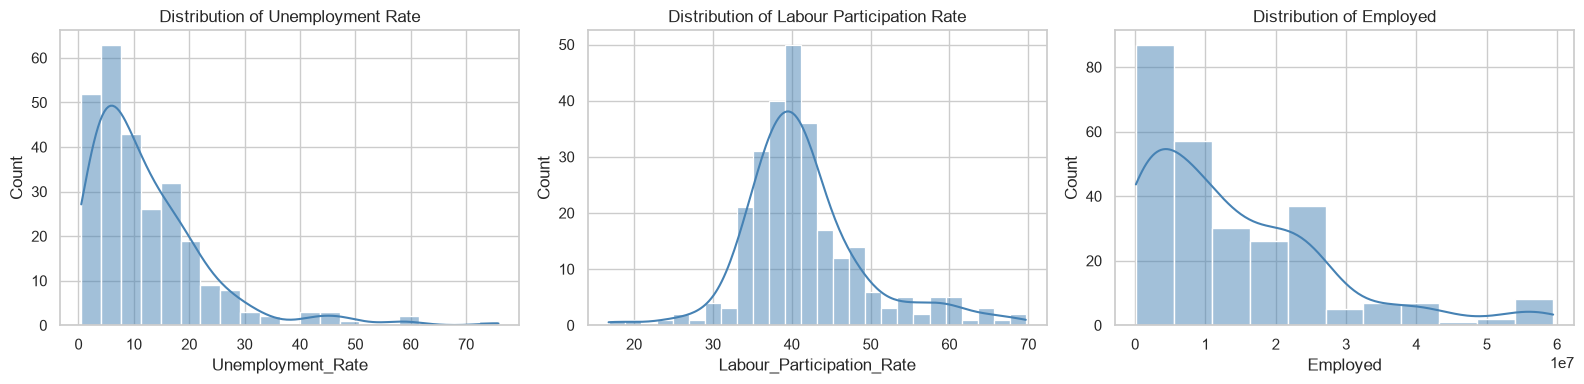

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cols = ["Unemployment_Rate", "Labour_Participation_Rate", "Employed"]
for ax, col in zip(axes, cols):
    sns.histplot(df_zone[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col.replace('_', ' ')}")
save_fig("distributions")

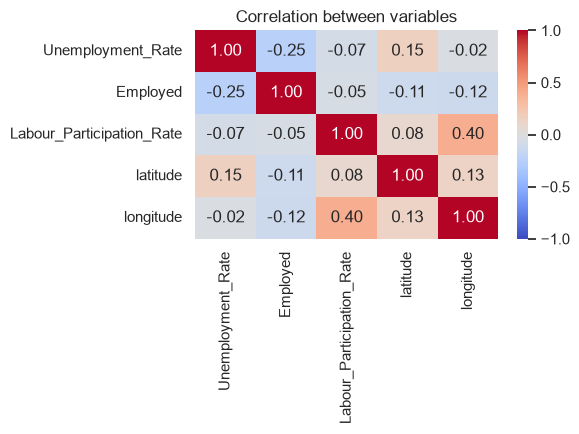

In [7]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df_zone[["Unemployment_Rate", "Employed", "Labour_Participation_Rate", "latitude", "longitude"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between variables")
save_fig("correlation_heatmap")

The unemployment rate is right-skewed: most months sit below 15%, with a long tail of extreme values. As shown below, almost all of that tail comes from the Covid-19 lockdown months.

## 4. Overall unemployment trend (May 2019 – Oct 2020)
The two files overlap from January to June 2020, so we use file 1 up to December 2019 and file 2 from January 2020. National figures are the average across states.

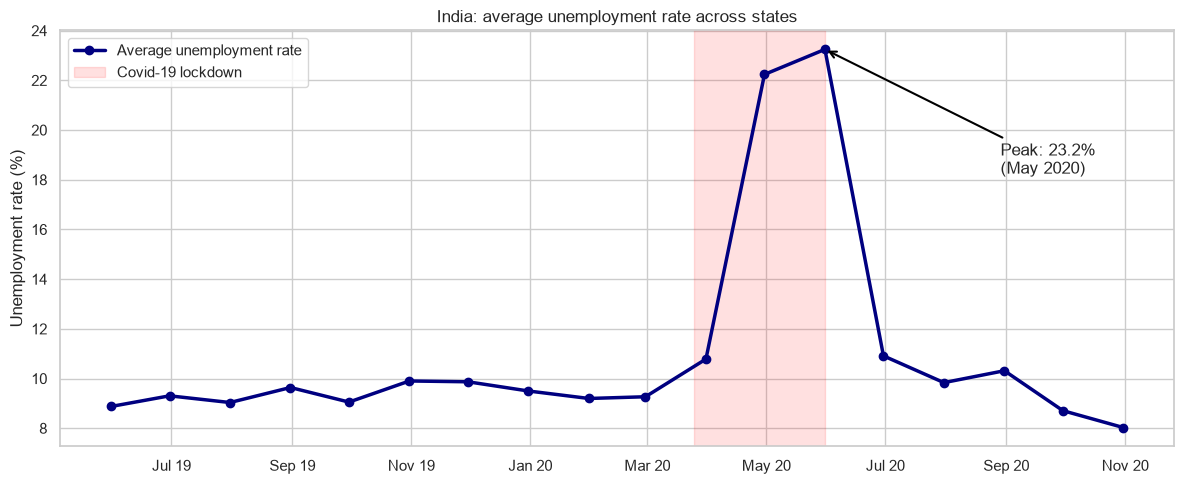

Date,2019-05-31,2019-06-30,2019-07-31,2019-08-31,2019-09-30,2019-10-31,2019-11-30,2019-12-31,2020-01-31,2020-02-29,2020-03-31,2020-04-30,2020-05-31,2020-06-30,2020-07-31,2020-08-31,2020-09-30,2020-10-31
Avg Unemployment Rate (%),8.87,9.3,9.03,9.64,9.05,9.9,9.87,9.5,9.2,9.27,10.78,22.24,23.24,10.91,9.83,10.31,8.71,8.03


In [8]:
trend_2019 = df_area[df_area["Date"] < "2020-01-01"].groupby("Date")["Unemployment_Rate"].mean()
trend_2020 = df_zone.groupby("Date")["Unemployment_Rate"].mean()
national = pd.concat([trend_2019, trend_2020]).sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(national.index, national.values, marker="o", linewidth=2.5, color="navy", label="Average unemployment rate")
shade_lockdown(ax)
peak = national.idxmax()
ax.annotate(f"Peak: {national.max():.1f}%\n({peak:%b %Y})", xy=(peak, national.max()),
            xytext=(peak + pd.Timedelta(days=90), national.max() - 5),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_title("India: average unemployment rate across states")
ax.set_ylabel("Unemployment rate (%)")
ax.legend()
save_fig("national_trend")
national.round(2).rename("Avg Unemployment Rate (%)").to_frame().T

## 5. Impact of Covid-19
We split 2020 (file 2) into three phases:
- **Pre-lockdown:** Jan – Mar 2020
- **Lockdown:** Apr – Jun 2020
- **Unlock / recovery:** Jul – Oct 2020

In [9]:
def phase(date):
    if date < pd.Timestamp("2020-04-01"):
        return "1. Pre-lockdown (Jan-Mar)"
    if date < pd.Timestamp("2020-07-01"):
        return "2. Lockdown (Apr-Jun)"
    return "3. Unlock (Jul-Oct)"


df_zone["Phase"] = df_zone["Date"].apply(phase)
# Jammu & Kashmir and Sikkim miss some months, so employment totals use only states with all 10 months
months_per_state = df_zone.groupby("State")["Date"].nunique()
complete_states = months_per_state[months_per_state == df_zone["Date"].nunique()].index
df_complete = df_zone[df_zone["State"].isin(complete_states)]
print(f"{len(complete_states)} states have data for every month; they are used for employment totals.")

phase_summary = df_zone.groupby("Phase")[["Unemployment_Rate", "Labour_Participation_Rate"]].mean()
phase_summary["Employed_Millions"] = df_complete.groupby(["Phase", "Date"])["Employed"].sum().groupby("Phase").mean() / 1e6
phase_summary = phase_summary.round(2)
phase_summary

25 states have data for every month; they are used for employment totals.


,Unemployment_Rate,Labour_Participation_Rate,Employed_Millions
Phase,,,
1. Pre-lockdown (Jan-Mar),9.76,44.18,397.17
2. Lockdown (Apr-Jun),18.75,38.76,317.53
3. Unlock (Jul-Oct),9.22,42.02,388.03


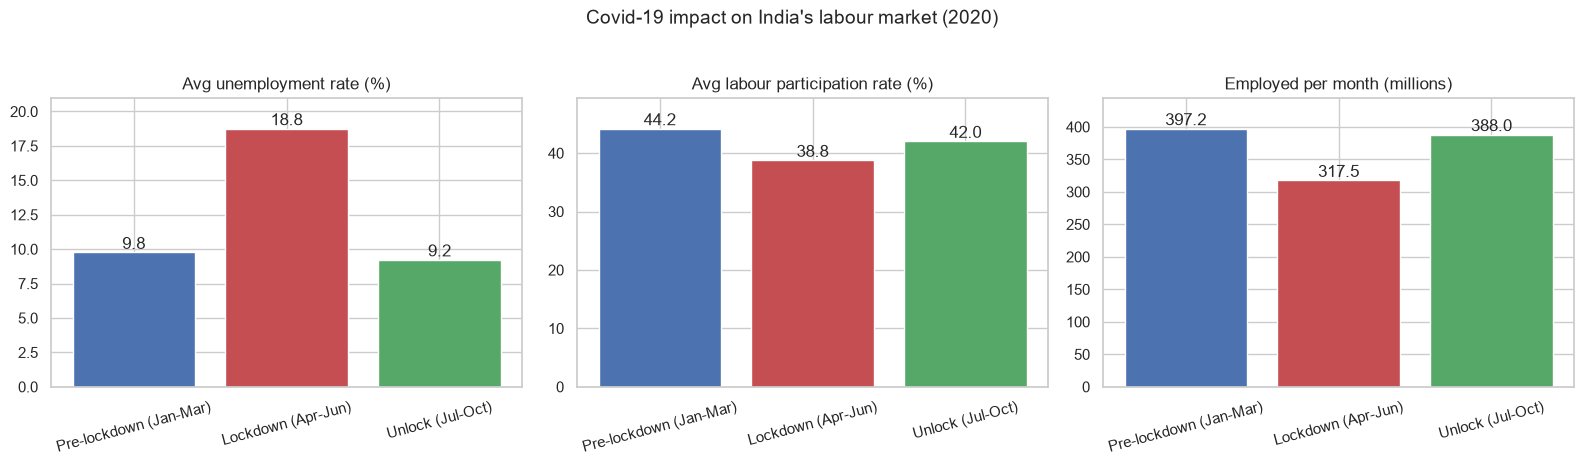

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
palette = ["#4c72b0", "#c44e52", "#55a868"]
for ax, col, title in zip(axes, phase_summary.columns,
                          ["Avg unemployment rate (%)", "Avg labour participation rate (%)", "Employed per month (millions)"]):
    bars = ax.bar(phase_summary.index.str[3:], phase_summary[col], color=palette)
    ax.bar_label(bars, fmt="%.1f")
    ax.margins(y=0.12)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)
plt.suptitle("Covid-19 impact on India's labour market (2020)", fontsize=14, y=1.03)
save_fig("covid_phase_impact")

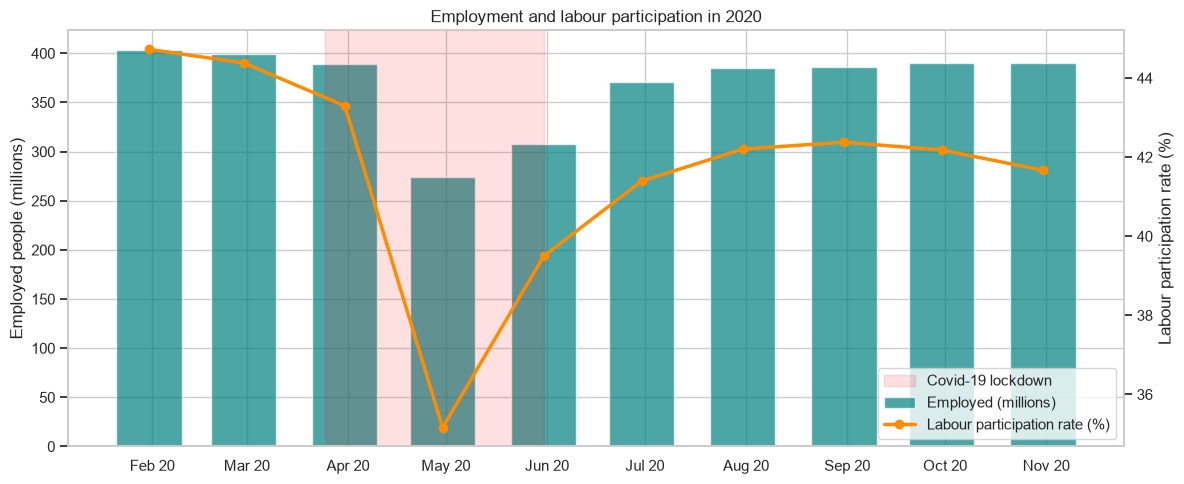

Employed people fell by about 114 million between March and April 2020 (states with complete data).


In [11]:
monthly = df_complete.groupby("Date").agg(Employed=("Employed", "sum"), LPR=("Labour_Participation_Rate", "mean"))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(monthly.index, monthly["Employed"] / 1e6, width=20, color="teal", alpha=0.7, label="Employed (millions)")
ax1.set_ylabel("Employed people (millions)")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["LPR"], color="darkorange", marker="o", linewidth=2.5, label="Labour participation rate (%)")
ax2.set_ylabel("Labour participation rate (%)")
ax2.grid(False)
shade_lockdown(ax1)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="lower right")
plt.title("Employment and labour participation in 2020")
save_fig("employment_participation")

jobs_lost = (monthly.loc["2020-03-31", "Employed"] - monthly.loc["2020-04-30", "Employed"]) / 1e6
print(f"Employed people fell by about {jobs_lost:.0f} million between March and April 2020 (states with complete data).")

### Which states were hit hardest?

In [12]:
state_phase = df_zone.pivot_table(index="State", columns="Phase", values="Unemployment_Rate", aggfunc="mean")
state_phase.columns = ["Pre-lockdown", "Lockdown", "Unlock"]
state_phase["Lockdown increase (pts)"] = state_phase["Lockdown"] - state_phase["Pre-lockdown"]
state_phase["Recovered (Unlock - Pre)"] = state_phase["Unlock"] - state_phase["Pre-lockdown"]
state_phase = state_phase.sort_values("Lockdown increase (pts)", ascending=False).round(2)
state_phase

,Pre-lockdown,Lockdown,Unlock,Lockdown increase (pts),Recovered (Unlock - Pre)
State,,,,,
Puducherry,1.18,46.09,9.40,44.91,8.22
Jharkhand,10.23,42.42,9.36,32.19,-0.87
Tamil Nadu,3.35,31.73,4.15,28.38,0.80
Bihar,12.11,36.81,11.99,24.70,-0.12
Karnataka,3.31,19.42,2.12,16.11,-1.18
Maharashtra,5.14,15.20,4.69,10.05,-0.45
Madhya Pradesh,3.63,13.61,4.20,9.97,0.57
Haryana,23.72,32.98,26.17,9.26,2.45
Goa,5.65,14.84,15.05,9.19,9.40


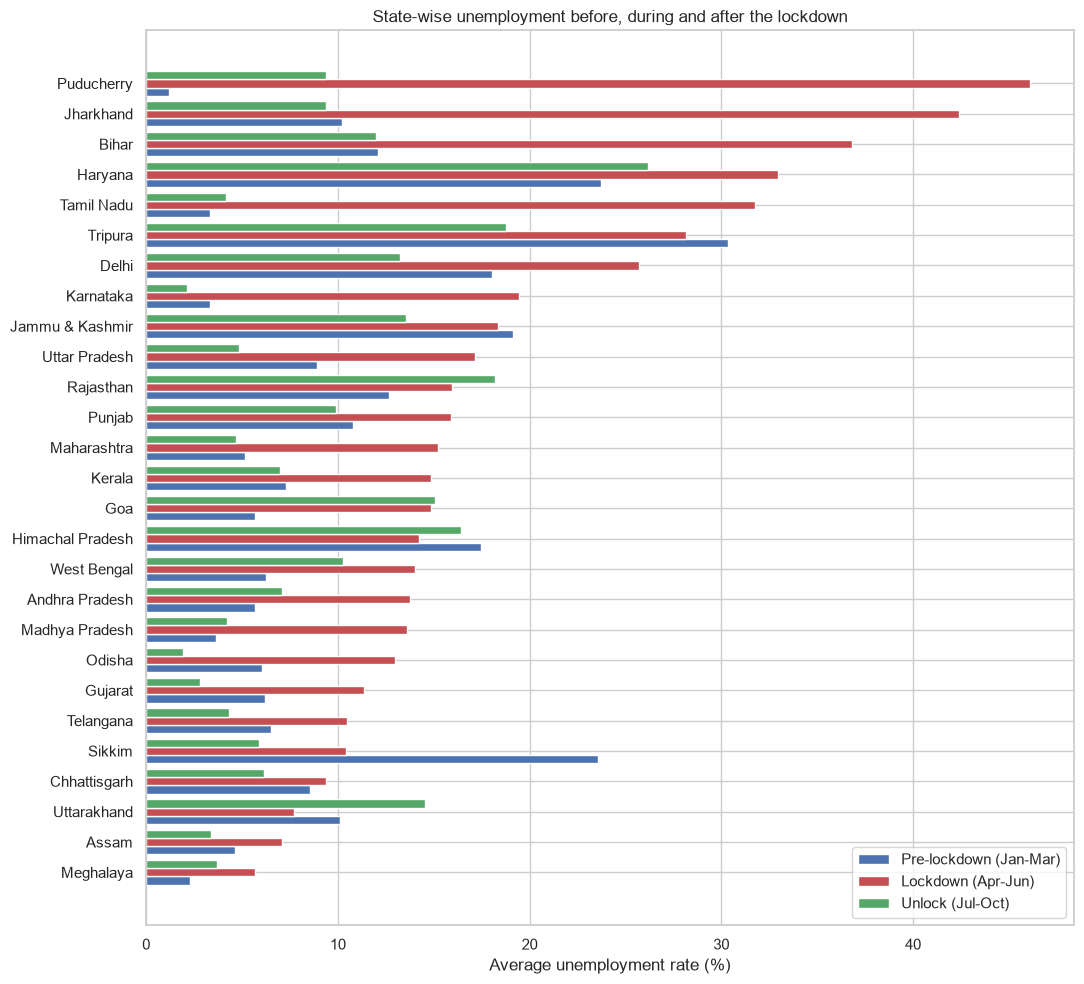

In [13]:
plot_df = state_phase.sort_values("Lockdown", ascending=True)
y = np.arange(len(plot_df))
plt.figure(figsize=(11, 10))
plt.barh(y - 0.27, plot_df["Pre-lockdown"], height=0.27, label="Pre-lockdown (Jan-Mar)", color="#4c72b0")
plt.barh(y, plot_df["Lockdown"], height=0.27, label="Lockdown (Apr-Jun)", color="#c44e52")
plt.barh(y + 0.27, plot_df["Unlock"], height=0.27, label="Unlock (Jul-Oct)", color="#55a868")
plt.yticks(y, plot_df.index)
plt.xlabel("Average unemployment rate (%)")
plt.title("State-wise unemployment before, during and after the lockdown")
plt.legend(loc="lower right")
save_fig("statewise_covid_impact")

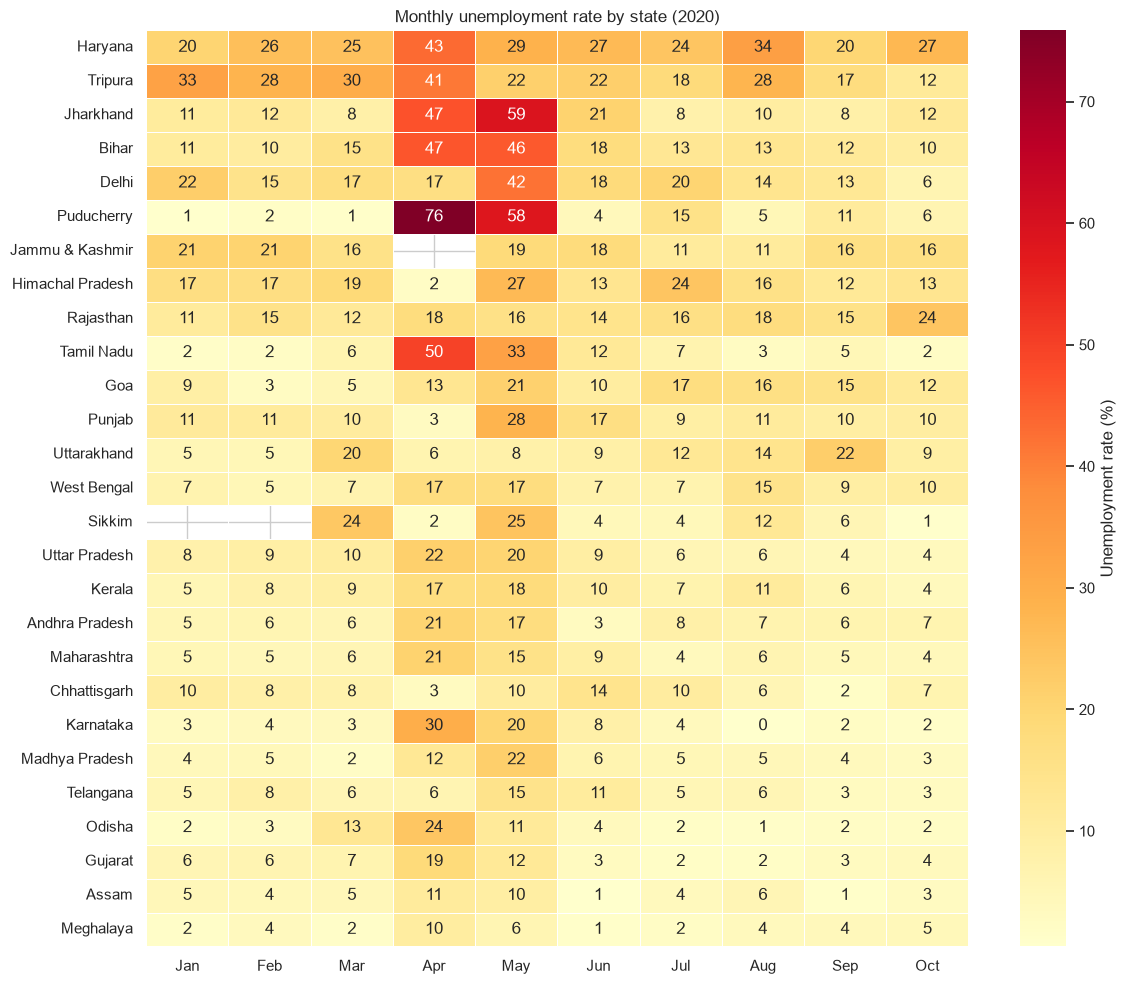

In [14]:
heat = df_zone.pivot_table(index="State", columns="Date", values="Unemployment_Rate")
heat.columns = heat.columns.strftime("%b")
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(12, 10))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=0.4, cbar_kws={"label": "Unemployment rate (%)"})
plt.title("Monthly unemployment rate by state (2020)")
plt.xlabel("")
plt.ylabel("")
save_fig("state_month_heatmap")

## 6. Zone-wise patterns

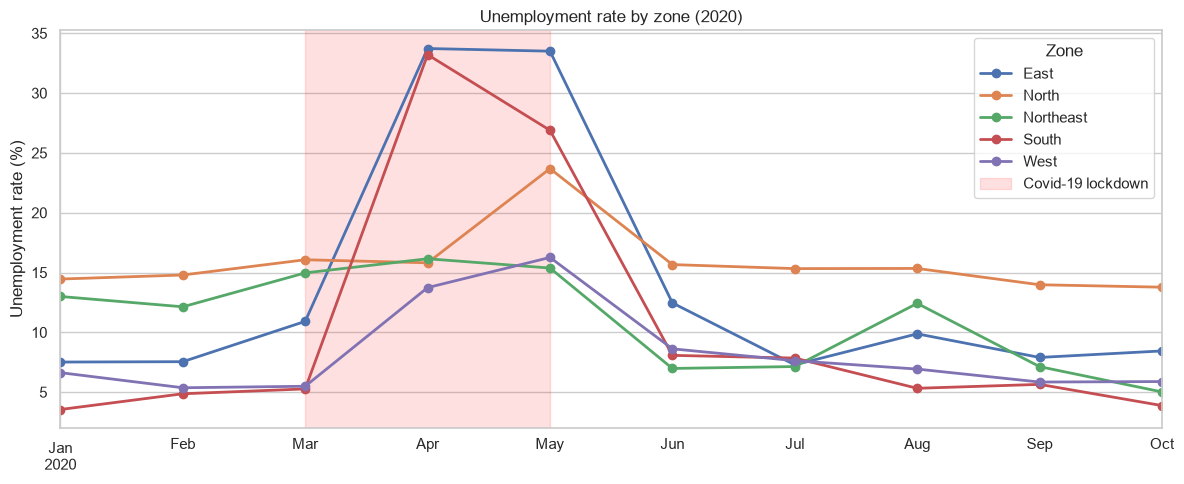

Date,2020-01-31,2020-02-29,2020-03-31,2020-04-30,2020-05-31,2020-06-30,2020-07-31,2020-08-31,2020-09-30,2020-10-31
Zone,,,,,,,,,,
East,7.5,7.5,10.9,33.7,33.5,12.5,7.3,9.9,7.9,8.4
North,14.5,14.8,16.1,15.8,23.7,15.7,15.3,15.3,14.0,13.8
Northeast,13.0,12.1,15.0,16.2,15.4,7.0,7.1,12.4,7.1,5.0
South,3.5,4.9,5.3,33.2,26.9,8.1,7.8,5.3,5.6,3.9
West,6.6,5.4,5.5,13.7,16.3,8.6,7.6,6.9,5.8,5.9


In [15]:
zone_trend = df_zone.groupby(["Date", "Zone"])["Unemployment_Rate"].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
zone_trend.plot(ax=ax, marker="o", linewidth=2)
shade_lockdown(ax)
ax.set_title("Unemployment rate by zone (2020)")
ax.set_ylabel("Unemployment rate (%)")
ax.set_xlabel("")
ax.legend(title="Zone")
save_fig("zone_trend")

zone_trend.T.round(1)

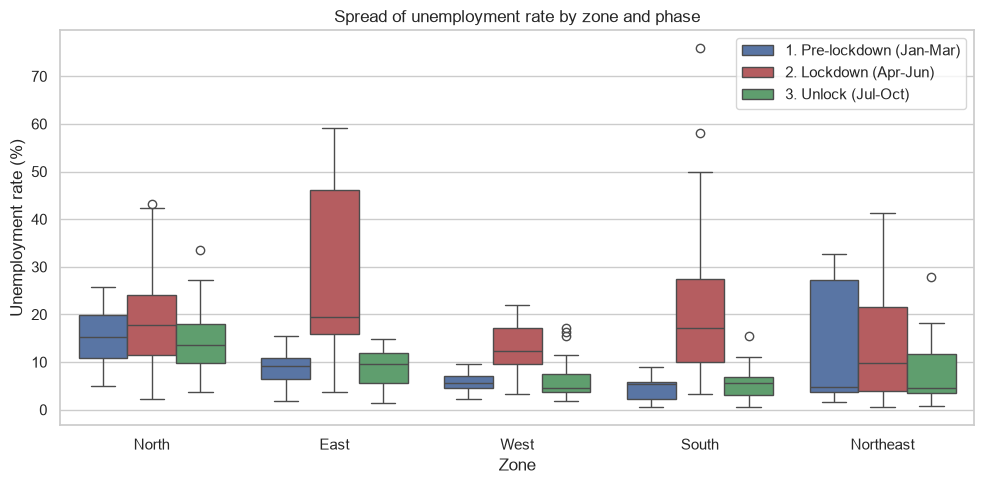

In [16]:
plt.figure(figsize=(10, 5))
order = df_zone.groupby("Zone")["Unemployment_Rate"].median().sort_values(ascending=False).index
sns.boxplot(data=df_zone, x="Zone", y="Unemployment_Rate", hue="Phase", order=order, palette=palette)
plt.title("Spread of unemployment rate by zone and phase")
plt.ylabel("Unemployment rate (%)")
plt.legend(title="", loc="upper right")
save_fig("zone_phase_boxplot")

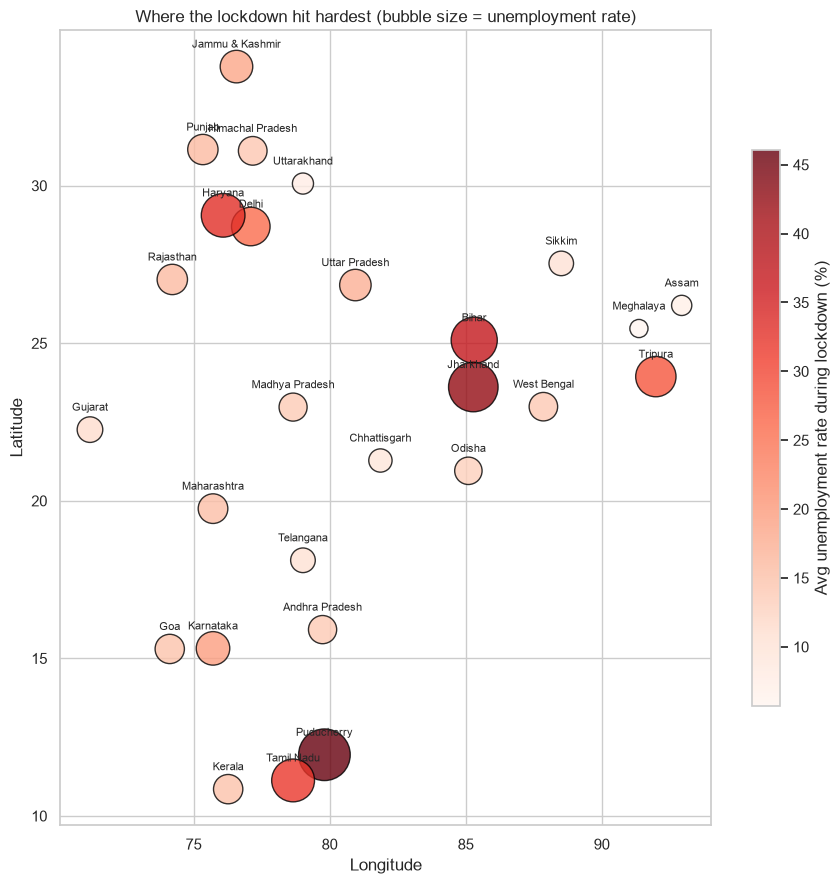

In [17]:
geo = df_zone[df_zone["Phase"].str.startswith("2")].groupby("State").agg(
    lat=("latitude", "first"), lon=("longitude", "first"),
    rate=("Unemployment_Rate", "mean"), zone=("Zone", "first"))

plt.figure(figsize=(9, 9))
sc = plt.scatter(geo["lon"], geo["lat"], s=geo["rate"] * 30, c=geo["rate"], cmap="Reds",
                 edgecolor="black", alpha=0.8)
for state, row in geo.iterrows():
    plt.text(row["lon"], row["lat"] + 0.6, state, fontsize=8, ha="center")
plt.colorbar(sc, label="Avg unemployment rate during lockdown (%)", shrink=0.7)
plt.title("Where the lockdown hit hardest (bubble size = unemployment rate)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
save_fig("lockdown_bubble_map")

## 7. Rural vs urban unemployment (May 2019 – Jun 2020)

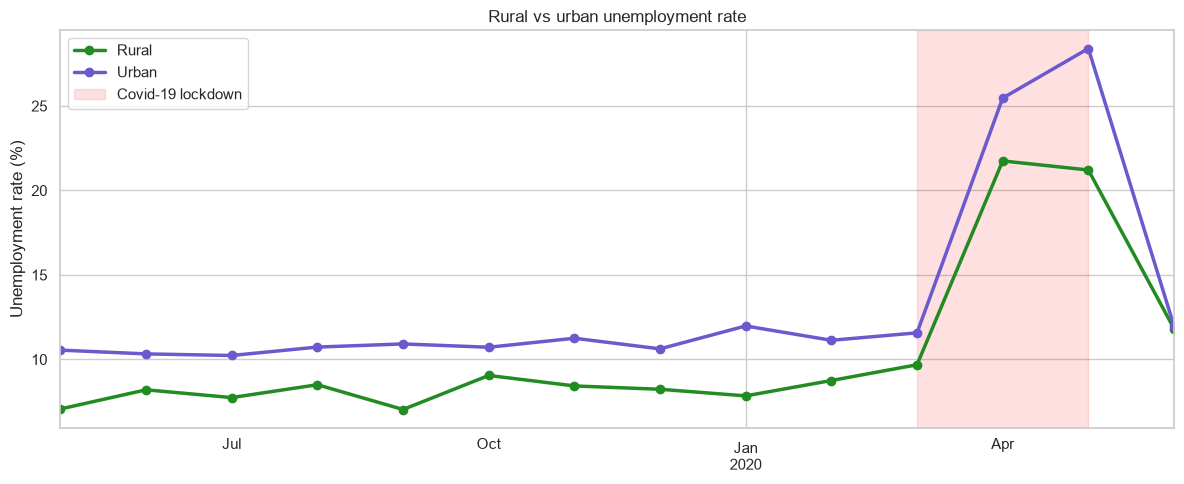

Period,Before lockdown,Lockdown (Apr-Jun 2020)
Area,,
Rural,8.23,18.26
Urban,10.91,22.08


In [18]:
area_trend = df_area.groupby(["Date", "Area"])["Unemployment_Rate"].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
area_trend.plot(ax=ax, marker="o", linewidth=2.5, color={"Rural": "forestgreen", "Urban": "slateblue"})
shade_lockdown(ax)
ax.set_title("Rural vs urban unemployment rate")
ax.set_ylabel("Unemployment rate (%)")
ax.set_xlabel("")
ax.legend()
save_fig("rural_vs_urban")

area_summary = df_area.assign(Period=np.where(df_area["Date"] < "2020-04-01", "Before lockdown", "Lockdown (Apr-Jun 2020)")) \
    .pivot_table(index="Area", columns="Period", values="Unemployment_Rate", aggfunc="mean").round(2)
area_summary

## 8. Seasonal patterns
The data covers only 18 months, and Covid-19 dominates 2020, so we cannot measure true yearly seasonality. Instead we look at the **pre-Covid months (May 2019 – Feb 2020)** to see month-to-month movement in a normal period.

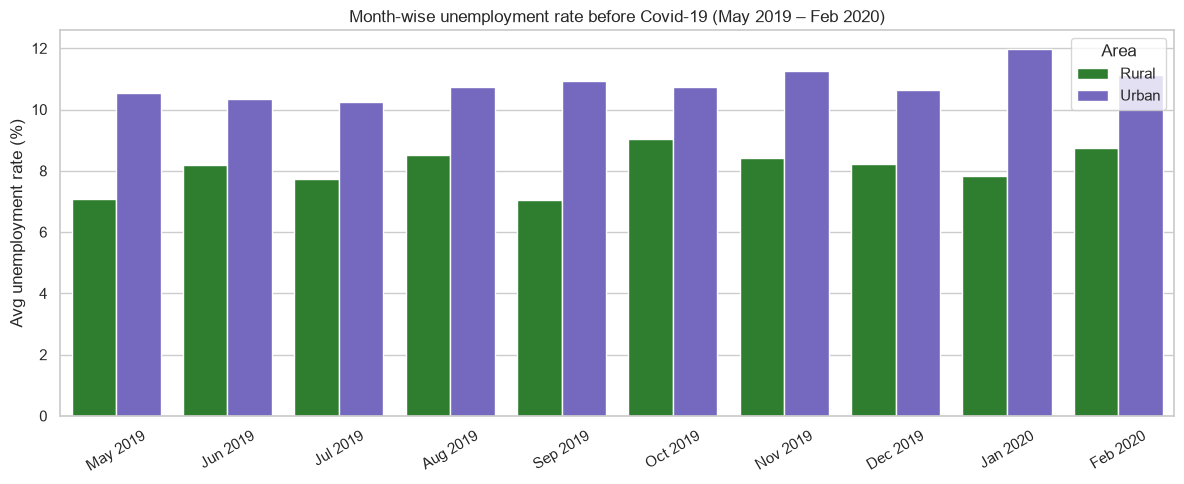

MonthLabel,May 2019,Jun 2019,Jul 2019,Aug 2019,Sep 2019,Oct 2019,Nov 2019,Dec 2019,Jan 2020,Feb 2020
Area,,,,,,,,,,
Rural,7.07,8.20,7.74,8.50,7.04,9.05,8.43,8.23,7.84,8.75
Urban,10.55,10.33,10.23,10.73,10.92,10.72,11.25,10.63,11.98,11.13


In [19]:
pre = df_area[df_area["Date"] < "2020-03-01"].copy()
pre["MonthLabel"] = pre["Date"].dt.strftime("%b %Y")
month_order = pre.sort_values("Date")["MonthLabel"].unique()

plt.figure(figsize=(12, 5))
sns.barplot(data=pre, x="MonthLabel", y="Unemployment_Rate", hue="Area", order=month_order,
            palette={"Rural": "forestgreen", "Urban": "slateblue"}, errorbar=None)
plt.title("Month-wise unemployment rate before Covid-19 (May 2019 – Feb 2020)")
plt.ylabel("Avg unemployment rate (%)")
plt.xlabel("")
plt.xticks(rotation=30)
save_fig("seasonal_pre_covid")

seasonal = pre.pivot_table(index="Area", columns="MonthLabel", values="Unemployment_Rate", aggfunc="mean")[month_order].round(2)
seasonal

In [20]:
volatility = df_area[df_area["Date"] < "2020-03-01"].groupby("State")["Unemployment_Rate"].agg(["mean", "std"]).round(2)
volatility.columns = ["Avg rate pre-Covid (%)", "Std deviation"]
print("States with the highest structural (pre-Covid) unemployment:")
volatility.sort_values("Avg rate pre-Covid (%)", ascending=False).head(8)

States with the highest structural (pre-Covid) unemployment:


,Avg rate pre-Covid (%),Std deviation
State,,
Tripura,29.01,3.82
Haryana,22.94,4.83
Himachal Pradesh,19.13,5.12
Jammu & Kashmir,17.22,4.98
Chandigarh,16.32,5.01
Jharkhand,14.28,5.99
Delhi,14.23,3.25
Bihar,13.83,3.91


## 9. Key numbers for the summary

In [21]:
pre_rate = phase_summary.loc["1. Pre-lockdown (Jan-Mar)", "Unemployment_Rate"]
lock_rate = phase_summary.loc["2. Lockdown (Apr-Jun)", "Unemployment_Rate"]
unlock_rate = phase_summary.loc["3. Unlock (Jul-Oct)", "Unemployment_Rate"]
print(f"Pre-lockdown average:  {pre_rate:.2f}%")
print(f"Lockdown average:      {lock_rate:.2f}%  ({lock_rate / pre_rate:.1f}x pre-lockdown)")
print(f"Unlock average:        {unlock_rate:.2f}%")
print(f"National peak:         {national.max():.2f}% in {national.idxmax():%B %Y}")
print(f"October 2020:          {national.iloc[-1]:.2f}%")
print("\nTop 5 states by lockdown increase (percentage points):")
print(state_phase["Lockdown increase (pts)"].head(5).to_string())
print("\nStates still above their pre-lockdown level in Jul-Oct:")
print(state_phase[state_phase["Recovered (Unlock - Pre)"] > 0]["Recovered (Unlock - Pre)"].sort_values(ascending=False).to_string())
print("\nZone with highest lockdown unemployment:",
      df_zone[df_zone["Phase"].str.startswith("2")].groupby("Zone")["Unemployment_Rate"].mean().idxmax())

Pre-lockdown average:  9.76%
Lockdown average:      18.75%  (1.9x pre-lockdown)
Unlock average:        9.22%
National peak:         23.24% in May 2020
October 2020:          8.03%

Top 5 states by lockdown increase (percentage points):
State
Puducherry    44.91
Jharkhand     32.19
Tamil Nadu    28.38
Bihar         24.70
Karnataka     16.11

States still above their pre-lockdown level in Jul-Oct:
State
Goa               9.40
Puducherry        8.22
Rajasthan         5.53
Uttarakhand       4.42
West Bengal       4.00
Haryana           2.45
Meghalaya         1.41
Andhra Pradesh    1.37
Tamil Nadu        0.80
Madhya Pradesh    0.57

Zone with highest lockdown unemployment: East


## 10. Insights and policy suggestions

### What the data shows
1. **Covid-19 caused an unemployment shock.** The average unemployment rate rose from **9.8%** before the lockdown (Jan–Mar 2020) to **18.8%** during it (Apr–Jun 2020), about 1.9 times higher. It peaked at **23.2% in May 2020**.
2. **Jobs and participation collapsed together.** In the 25 states with complete data, about **114 million fewer people were employed in April 2020 than in March**. Labour participation fell from 44.2% to 38.8%, so many people stopped looking for work altogether. Official unemployment numbers therefore understate the real damage.
3. **Recovery was fast but uneven.** By October 2020 the average rate was back to **8.0%**, below pre-Covid levels. However, **Goa, Puducherry, Rajasthan, Uttarakhand and West Bengal** were still noticeably above their pre-lockdown rates during Jul–Oct.
4. **Hardest-hit states:** Puducherry (+44.9 points), Jharkhand (+32.2), Tamil Nadu (+28.4), Bihar (+24.7) and Karnataka (+16.1). By zone, the **East** and **South** saw the sharpest spikes, above 33% in April 2020.
5. **Some states have a structural problem that predates Covid.** Tripura (29%), Haryana (23%), Himachal Pradesh (19%), Jammu & Kashmir (17%) and Delhi (14%) already had high unemployment in 2019. The North zone stays the highest even after recovery (about 14%).
6. **Urban unemployment is consistently higher than rural** (10.9% vs 8.2% before the lockdown; 22.1% vs 18.3% during it). Cities were hit harder because informal service jobs such as retail, hospitality, construction and domestic work disappeared overnight.
7. **Seasonal pattern:** before Covid, the **urban rate stays in a narrow band (10.2–12.0%)**, while the **rural rate swings more (7.0–9.1%)**. Rural unemployment is lowest in May and September and highest in October and February, which fits the seasonal nature of farm work. With only one normal year of data this is an indication, not a proven seasonal cycle.

### Policy suggestions
- **Targeted relief for the hardest-hit states** (Puducherry, Jharkhand, Tamil Nadu, Bihar), linked to the size of their lockdown spike rather than a flat national allocation.
- **Urban employment guarantee:** extend a MGNREGA-style scheme to cities, since urban workers were hit hardest and have no equivalent safety net.
- **Strengthen rural work schemes in lean agricultural months** to smooth the seasonal swings in rural unemployment.
- **Long-term job creation in structurally high-unemployment states** (Tripura, Haryana, Himachal Pradesh, J&K) through skills training, MSME support and local industry, because their problem is not just Covid.
- **Track labour participation alongside unemployment** in future crises. A falling participation rate signals hidden unemployment that the headline rate misses.
- **Build an early-warning dashboard** with monthly state-level data like this, so relief can reach states within weeks of a shock.

### Limitations
- National figures are simple averages across states, not weighted by population.
- The two files use slightly different state coverage (28 vs 27 regions).
- About 18 months of data is too short to confirm true yearly seasonality.